Adding the first code cell

In [1]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "mvtec-ad" / "bottle"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Use Apple's Metal GPU when available
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Image settings
IMAGE_SIZE = 128
BATCH_SIZE = 16

print("Device:", DEVICE)
print("Training images:", DATA_ROOT / "train" / "good")
print("Model output directory:", MODEL_DIR)


Device: mps
Training images: /Users/anupamguptaroy17/Projects/VisionQC/data/raw/mvtec-ad/bottle/train/good
Model output directory: /Users/anupamguptaroy17/Projects/VisionQC/models


Creating the Training Dataset Loader

In [2]:

class BottleDataset(Dataset):
    """Loads normal bottle images for autoencoder training."""

    def __init__(self, image_dir, image_size=128):
        self.image_paths = sorted(Path(image_dir).glob("*.png"))

        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        # The autoencoder will learn to reconstruct this same image.
        return image


train_dataset = BottleDataset(
    DATA_ROOT / "train" / "good",
    image_size=IMAGE_SIZE,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

print("Training images loaded:", len(train_dataset))
print("Number of batches:", len(train_loader))

# Inspect one batch
sample_batch = next(iter(train_loader))
print("Batch shape:", sample_batch.shape)
print("Pixel range:", sample_batch.min().item(), "to", sample_batch.max().item())


Training images loaded: 209
Number of batches: 14
Batch shape: torch.Size([16, 3, 128, 128])
Pixel range: 0.11764705926179886 to 1.0


Building the autoencoder model

In [3]:

class BottleAutoencoder(nn.Module):
    """Convolutional autoencoder for bottle anomaly detection."""

    def __init__(self):
        super().__init__()

        # Encoder: compress the input image into a smaller representation.
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),
        )

        # Decoder: reconstruct the original image dimensions.
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                128, 64, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                64, 32, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                32, 16, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                16, 3, kernel_size=4, stride=2, padding=1
            ),
            nn.Sigmoid(),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        reconstructed = self.decoder(encoded)
        return reconstructed


model = BottleAutoencoder().to(DEVICE)

# Check that the model reconstructs an image of the expected shape.
with torch.no_grad():
    sample_input = sample_batch[:1].to(DEVICE)
    sample_output = model(sample_input)

print("Model device:", next(model.parameters()).device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Trainable parameters:", sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
))


Model device: mps:0
Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 3, 128, 128])
Trainable parameters: 270355


Configuring the training process

In [4]:

# Loss function: measures the difference between original
# and reconstructed bottle images.
criterion = nn.MSELoss()

# Adam optimiser updates the model's weights during training.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of complete passes through the training dataset.
NUM_EPOCHS = 30

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", NUM_EPOCHS)
print("Device:", DEVICE)


Loss function: MSELoss()
Optimiser: Adam
Learning rate: 0.001
Epochs: 30
Device: mps


Train the autoencoder

In [5]:

# Store the average reconstruction loss for each epoch.
epoch_losses = []

model.train()

for epoch in range(NUM_EPOCHS):
    running_loss = 0.0

    for images in train_loader:
        images = images.to(DEVICE)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Reconstruct the input images.
        reconstructed = model(images)

        # Compare reconstructed images against original images.
        loss = criterion(reconstructed, images)

        # Calculate gradients and update model weights.
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    # Average loss across the entire training dataset.
    epoch_loss = running_loss / len(train_dataset)
    epoch_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"Loss: {epoch_loss:.6f}"
    )

print("\nTraining complete!")
print(f"Final training loss: {epoch_losses[-1]:.6f}")


Epoch [01/30] Loss: 0.128663
Epoch [02/30] Loss: 0.067919
Epoch [03/30] Loss: 0.025602
Epoch [04/30] Loss: 0.011891
Epoch [05/30] Loss: 0.007644
Epoch [06/30] Loss: 0.005580
Epoch [07/30] Loss: 0.004465
Epoch [08/30] Loss: 0.003792
Epoch [09/30] Loss: 0.003945
Epoch [10/30] Loss: 0.003007
Epoch [11/30] Loss: 0.003036
Epoch [12/30] Loss: 0.002899
Epoch [13/30] Loss: 0.002524
Epoch [14/30] Loss: 0.002599
Epoch [15/30] Loss: 0.002500
Epoch [16/30] Loss: 0.002342
Epoch [17/30] Loss: 0.002349
Epoch [18/30] Loss: 0.002405
Epoch [19/30] Loss: 0.002166
Epoch [20/30] Loss: 0.002171
Epoch [21/30] Loss: 0.002335
Epoch [22/30] Loss: 0.002172
Epoch [23/30] Loss: 0.002089
Epoch [24/30] Loss: 0.002139
Epoch [25/30] Loss: 0.002229
Epoch [26/30] Loss: 0.002083
Epoch [27/30] Loss: 0.002048
Epoch [28/30] Loss: 0.002000
Epoch [29/30] Loss: 0.002020
Epoch [30/30] Loss: 0.002151

Training complete!
Final training loss: 0.002151


Visualising the reconstruction

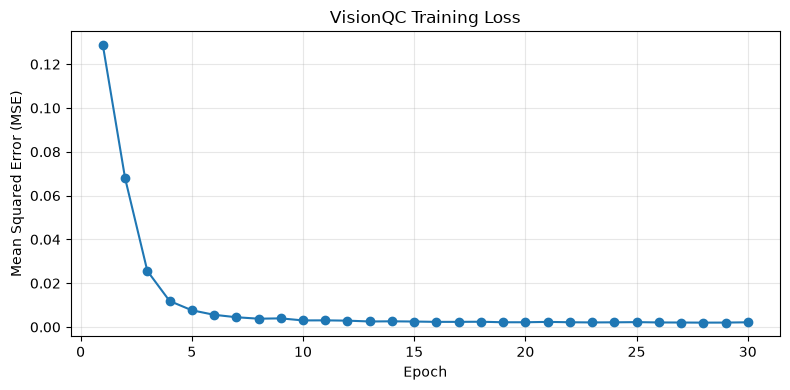

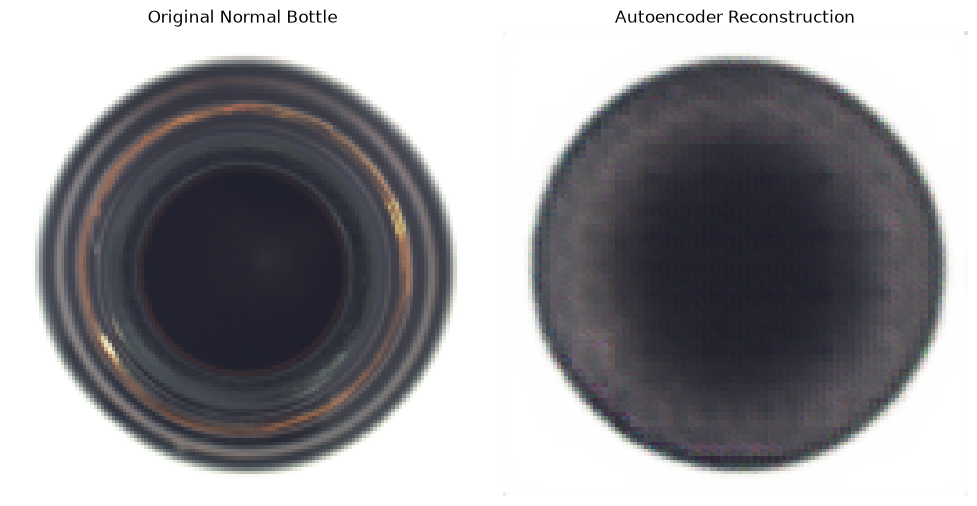

In [6]:

# Plot training loss across epochs.
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
plt.title("VisionQC Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compare an original normal bottle with its reconstruction.
model.eval()

with torch.no_grad():
    original = sample_batch[:1].to(DEVICE)
    reconstructed = model(original)

original_image = original[0].cpu().permute(1, 2, 0).numpy()
reconstructed_image = reconstructed[0].cpu().permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Normal Bottle")
axes[0].axis("off")

axes[1].imshow(reconstructed_image)
axes[1].set_title("Autoencoder Reconstruction")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Comparing normal and defective bottles

In [7]:

# Load one normal and one defective test image.
normal_path = DATA_ROOT / "test" / "good" / "000.png"
defect_path = DATA_ROOT / "test" / "broken_small" / "002.png"

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

def load_bottle_image(path):
    with Image.open(path) as image:
        return transform(image.convert("RGB")).unsqueeze(0)

normal_image = load_bottle_image(normal_path).to(DEVICE)
defect_image = load_bottle_image(defect_path).to(DEVICE)

# Reconstruct both images.
model.eval()

with torch.no_grad():
    normal_reconstruction = model(normal_image)
    defect_reconstruction = model(defect_image)

    normal_error_map = (normal_image - normal_reconstruction).pow(2).mean(dim=1)
    defect_error_map = (defect_image - defect_reconstruction).pow(2).mean(dim=1)

    normal_score = normal_error_map.mean().item()
    defect_score = defect_error_map.mean().item()

print(f"Normal bottle reconstruction error: {normal_score:.6f}")
print(f"Defective bottle reconstruction error: {defect_score:.6f}")

if defect_score > normal_score:
    print("This defective sample has a higher reconstruction error.")
else:
    print("This defective sample does not have a higher reconstruction error.")


Normal bottle reconstruction error: 0.002241
Defective bottle reconstruction error: 0.003096
This defective sample has a higher reconstruction error.


Visualising the results

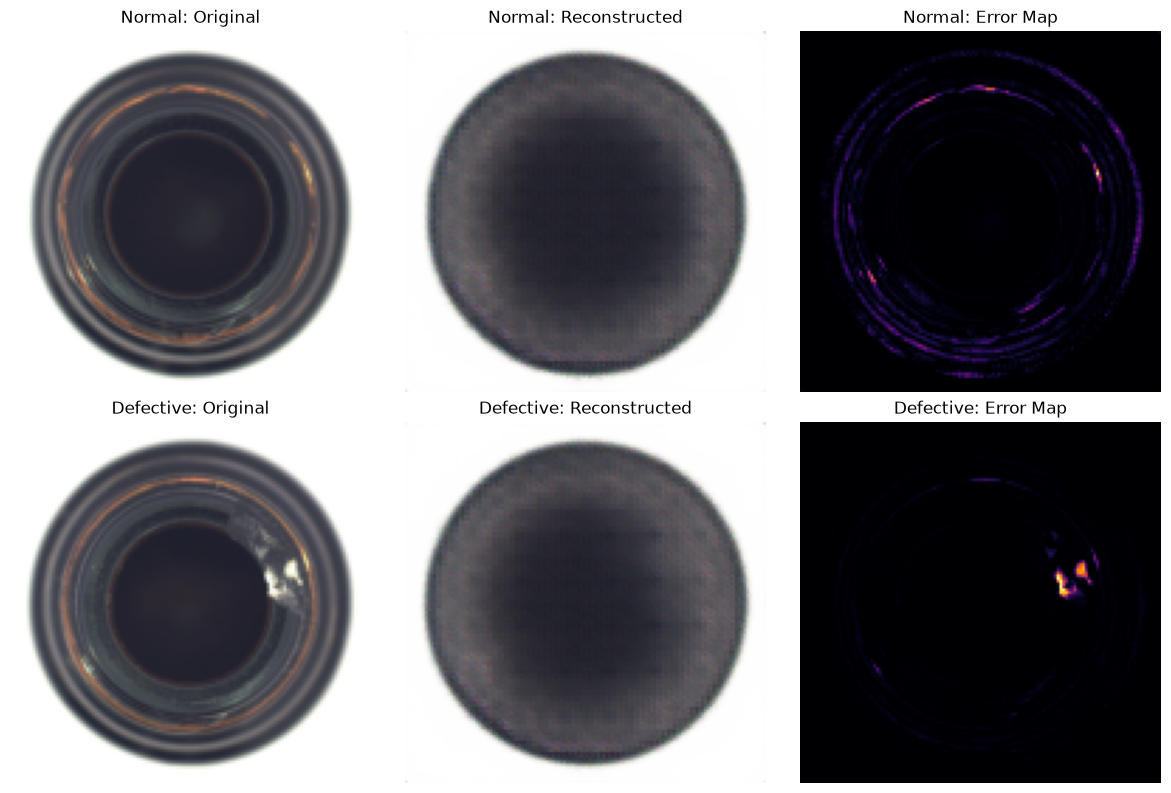

In [8]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

images = [
    normal_image, normal_reconstruction, normal_error_map,
    defect_image, defect_reconstruction, defect_error_map,
]

titles = [
    "Normal: Original", "Normal: Reconstructed", "Normal: Error Map",
    "Defective: Original", "Defective: Reconstructed", "Defective: Error Map",
]

for ax, image, title in zip(axes.flat, images, titles):
    array = image[0].detach().cpu().numpy()

    if array.ndim == 3 and array.shape[0] == 3:
        array = np.transpose(array, (1, 2, 0))
        ax.imshow(array)
    else:
        ax.imshow(array, cmap="inferno")

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Evaluating all 83 Images

In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

# Calculate reconstruction scores for individual images.
def get_reconstruction(image_tensor):
    with torch.no_grad():
        image_tensor = image_tensor.to(DEVICE)
        reconstruction = model(image_tensor)
        error_map = (image_tensor - reconstruction).pow(2).mean(dim=1)
    return error_map[0].cpu().numpy()


def load_image_tensor(path):
    with Image.open(path) as image:
        return transform(image.convert("RGB"))


model.eval()

# 1. Calibrate a provisional threshold using normal training images.
train_scores = []

for path in sorted((DATA_ROOT / "train" / "good").glob("*.png")):
    tensor = load_image_tensor(path).unsqueeze(0)
    error_map = get_reconstruction(tensor)
    train_scores.append(error_map.mean())

threshold = float(np.percentile(train_scores, 99))

print(f"Provisional anomaly threshold: {threshold:.6f}")

# 2. Evaluate every test image.
true_labels = []
predicted_labels = []
image_scores = []
pixel_errors = []
pixel_labels = []

for category in sorted(p.name for p in (DATA_ROOT / "test").iterdir()
                        if p.is_dir()):
    for path in sorted((DATA_ROOT / "test" / category).glob("*.png")):
        is_defective = category != "good"

        tensor = load_image_tensor(path).unsqueeze(0)
        error_map = get_reconstruction(tensor)
        score = float(error_map.mean())

        true_labels.append(int(is_defective))
        predicted_labels.append(int(score > threshold))
        image_scores.append(score)

        # Compare error-map pixels with ground-truth masks.
        if is_defective:
            mask_path = (
                DATA_ROOT / "ground_truth" / category /
                f"{path.stem}_mask.png"
            )
            with Image.open(mask_path) as mask_image:
                mask_image = mask_image.convert("L").resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    Image.Resampling.NEAREST,
                )
                mask = np.asarray(mask_image) > 0
        else:
            mask = np.zeros(
                (IMAGE_SIZE, IMAGE_SIZE), dtype=bool
            )

        pixel_errors.extend(error_map.ravel())
        pixel_labels.extend(mask.ravel())

# 3. Report image-level detection metrics.
print("\nIMAGE-LEVEL RESULTS")
print("Test images:", len(true_labels))
print(f"Accuracy:  {accuracy_score(true_labels, predicted_labels):.3f}")
print(f"Precision: {precision_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"Recall:    {recall_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"F1 score:  {f1_score(true_labels, predicted_labels, zero_division=0):.3f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(true_labels, predicted_labels))

# 4. Report ranking performance and pixel-level localisation.
print("\nLOCALISATION RESULTS")
try:
    pixel_auc = roc_auc_score(pixel_labels, pixel_errors)
    print(f"Pixel-level ROC-AUC: {pixel_auc:.3f}")
except ValueError:
    print("Pixel-level ROC-AUC could not be calculated.")

print("\nEvaluation complete.")


Provisional anomaly threshold: 0.002653

IMAGE-LEVEL RESULTS
Test images: 83
Accuracy:  0.651
Precision: 0.947
Recall:    0.571
F1 score:  0.713
Confusion matrix [[TN, FP], [FN, TP]]:
[[18  2]
 [27 36]]

LOCALISATION RESULTS
Pixel-level ROC-AUC: 0.771

Evaluation complete.


Comparing different thresolds

In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

thresholds = [
    threshold * 0.50,
    threshold * 0.65,
    threshold * 0.80,
    threshold,
    threshold * 1.20,
]

print(f"{'Threshold':>12} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'False alarms':>14} {'Missed defects':>15}")

for t in thresholds:
    predictions = (np.array(image_scores) > t).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        true_labels, predictions, labels=[0, 1]
    ).ravel()

    print(
        f"{t:12.6f} "
        f"{accuracy_score(true_labels, predictions):10.3f} "
        f"{precision_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{recall_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{f1_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{fp:14d} {fn:15d}"
    )


   Threshold   Accuracy  Precision     Recall         F1   False alarms  Missed defects
    0.001327      0.759      0.759      1.000      0.863             20               0
    0.001725      0.759      0.759      1.000      0.863             20               0
    0.002123      0.771      0.814      0.905      0.857             13               6
    0.002653      0.651      0.947      0.571      0.713              2              27
    0.003184      0.506      1.000      0.349      0.518              0              41
